# Experimento 01 — Baseline pre-compra

Este cuaderno corre el pipeline completo del Entregable II utilizando **solo los predictores disponibles en el momento de la compra**: estado del cliente, categoría del producto, método y valor del pago, flete estimado, fecha estimada de entrega y atributos físicos del producto. No incluye distancia geográfica ni historial del vendedor; esas extensiones se abordan en experimentos posteriores.

El resultado de esta corrida es la **línea base** contra la que se comparan las mejoras. Las tablas se persisten en `outputs/experimentos/01_baseline_pre_compra/`.

El cuaderno está pensado para ejecutarse de arriba abajo. Cada celda hace un paso puntual, de modo que al reejecutar no se reinicializa todo el flujo. En modo rápido se trabaja con 15 000 pedidos distribuidos cronológicamente; cambie `MAX_ROWS = None` para usar todo el dataset.

## 1. Entorno y datos

Detectamos si la ejecución es local o en Colab y resolvemos la ruta raíz del repositorio para que los imports de `src` funcionen igual en ambos casos. Si los CSV de Olist no están en `data/raw/` se descargan desde la API pública de Kaggle.

In [1]:
from pathlib import Path
import os
import subprocess
import sys

In [2]:
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/Cde571/LogisTech-Modelos-Simulacion-II.git'

if IN_COLAB:
    root = Path('/content/LogisTech-Modelos-Simulacion-II')
    if not root.exists():
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(root)], check=True)
    else:
        subprocess.run(['git', '-C', str(root), 'pull', '--ff-only'], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(root / 'requirements.txt')], check=True)
    os.chdir(root)
else:
    root = Path.cwd()
    while root.name in ('experimentos', 'notebook', 'notebooks'):
        root = root.parent
    os.chdir(root)

print('Raíz del repositorio:', root)

Raíz del repositorio: /home/mateo/Documentos/UdeA/ModelosSimulaciónII/proyectoEntregas/LogisTech-Modelos-Simulacion-II


In [3]:
import urllib.request
import zipfile

In [4]:
raw = root / 'data' / 'raw'
required = raw / 'olist_orders_dataset.csv'

if not required.exists():
    raw.mkdir(parents=True, exist_ok=True)
    archive = root / 'data' / 'olist.zip'
    urllib.request.urlretrieve(
        'https://www.kaggle.com/api/v1/datasets/download/olistbr/brazilian-ecommerce',
        archive,
    )
    with zipfile.ZipFile(archive) as bundle:
        bundle.extractall(raw)

print('CSV disponibles en data/raw:', len(list(raw.glob('*.csv'))))

CSV disponibles en data/raw: 9


## 2. Configuración y dataset a nivel de pedido

`ExperimentConfig` encapsula las decisiones reproducibles: tamaño de muestra, número de particiones de validación cruzada temporal y repeticiones del bootstrap para los intervalos de confianza. Después cargamos las nueve tablas de Olist y las agregamos en una fila por pedido con `build_order_level_dataset`, que incluye la lógica de agregación segura (sin fugas de información posteriores a la compra) y deriva los targets `delivery_time_days` y `late_delivery`.

In [5]:
from src.models import ExperimentConfig
from src.preprocessing import build_order_level_dataset, load_olist_tables, modeling_frame

In [6]:
MAX_ROWS = None  # Use None para la corrida completa.

config = ExperimentConfig(
    max_rows=MAX_ROWS,
    cv_splits=3,
    bootstrap_iterations=500,
)
config

ExperimentConfig(random_state=42, max_rows=None, cv_splits=3, bootstrap_iterations=500, min_frequency=20, low_cardinality_max=30, high_cardinality_min=100, selection_criterion='mean')

In [7]:
tables = load_olist_tables(raw)
list(tables.keys())

['orders',
 'items',
 'customers',
 'products',
 'payments',
 'sellers',
 'reviews',
 'geolocation',
 'category_translation']

In [8]:
orders = build_order_level_dataset(tables)
assert orders['order_id'].is_unique, 'Se esperaba una fila por pedido'

print(f'Pedidos agregados: {len(orders):,}')
print(f'Periodo: {orders.order_purchase_timestamp.min()} a {orders.order_purchase_timestamp.max()}')
orders.head(3)

Pedidos agregados: 99,441
Periodo: 2016-09-04 21:15:19 a 2018-10-17 17:30:18


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time_days,late_delivery,...,mean_product_width_cm,payment_type,payment_installments,payment_value,payment_records,purchase_year,purchase_month,purchase_dayofweek,purchase_hour,estimated_delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,0,...,13.0,voucher,1.0,38.71,3.0,2017,10,0,10,15.544063
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,0,...,19.0,boleto,1.0,141.46,1.0,2018,7,1,20,19.137766
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,0,...,21.0,credit_card,3.0,179.12,1.0,2018,8,2,8,26.639711


## 3. Regresión — días hasta la entrega

El objetivo `delivery_time_days` es la diferencia en días entre la compra y la entrega efectiva. `run_task` encadena muestreo temporal, partición 60/20/20, ajuste de hiperparámetros con validación cruzada, entrenamiento final, bootstrap de intervalos y análisis de importancia. Se exploran las cinco familias requeridas (Ridge, KNN, Random Forest, MLP y LinearSVR) y se compara el pipeline completo contra representaciones PCA/UMAP sobre los dos mejores modelos.

In [9]:
from src.experiments import run_task

In [10]:
X_reg, y_reg, dates_reg = modeling_frame(orders, 'delivery_time_days')
print(f'Filas: {len(X_reg):,} · Columnas predictoras: {X_reg.shape[1]}')
X_reg.head(3)

Filas: 96,476 · Columnas predictoras: 19


,customer_city,customer_state,product_category_name,payment_type,payment_installments,payment_value,payment_records,item_count,seller_count,total_price,total_freight_value,mean_product_weight_g,mean_product_length_cm,mean_product_height_cm,mean_product_width_cm,purchase_month,purchase_dayofweek,purchase_hour,estimated_delivery_days
30710,sao joaquim da barra,SP,beleza_saude,NaN,NaN,NaN,NaN,3.0,1.0,134.97,8.49,1000.0,16.0,16.0,16.0,9,3,12,18.488449
93285,sao paulo,SP,relogios_presentes,boleto,1.0,45.46,1.0,1.0,1.0,29.90,15.56,300.0,16.0,16.0,16.0,10,0,9,23.593866
28424,panambi,RS,esporte_lazer,boleto,1.0,39.09,1.0,1.0,1.0,21.90,17.19,400.0,16.0,16.0,16.0,10,0,16,34.293866


In [11]:
reg = run_task('regression', X_reg, y_reg, dates_reg, config)
list(reg.keys())

/home/mateo/Documentos/UdeA/ModelosSimulaciónII/proyectoEntregas/LogisTech-Modelos-Simulacion-II/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/home/mateo/Documentos/UdeA/ModelosSimulaciónII/proyectoEntregas/LogisTech-Modelos-Simulacion-II/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/mateo/Documentos/UdeA/ModelosSimulaciónII/proyectoEntregas/LogisTech-Modelos-Simulacion-II/.venv/lib/python3.13/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


/home/mateo/Documentos/UdeA/ModelosSimulaciónII/proyectoEntregas/LogisTech-Modelos-Simulacion-II/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


['parts',
 'cv_results',
 'ranking',
 'models',
 'feature_importance',
 'reductions']

In [12]:
reg['cv_results']

,model,params,primary_cv_mean,primary_cv_worst,primary_cv_ci95_low,primary_cv_ci95_high,fit_seconds,validation_MAE,validation_RMSE,validation_R2
0,Random Forest (ensamble),"{'max_depth': 12, 'min_samples_leaf': 5}",-5.657737,-6.427912,-7.419033,-3.896441,15.143291,5.657737,8.979363,0.185494
1,MLP (red neuronal),"{'alpha': 0.0001, 'hidden_layer_sizes': (64, 3...",-5.676251,-6.622851,-7.823539,-3.528963,10.558754,5.676251,8.877724,0.203807
2,Random Forest (ensamble),"{'max_depth': 24, 'min_samples_leaf': 5}",-5.689775,-6.459705,-7.466738,-3.912812,20.675088,5.689775,8.975932,0.186257
3,Random Forest (ensamble),"{'max_depth': None, 'min_samples_leaf': 5}",-5.690727,-6.460240,-7.466634,-3.914819,20.623532,5.690727,8.975459,0.186343
4,Ridge (parametrico),{'alpha': 10.0},-5.692780,-6.525553,-7.668636,-3.716924,1.510185,5.692780,9.019293,0.180142
5,Random Forest (ensamble),"{'max_depth': 12, 'min_samples_leaf': 2}",-5.693100,-6.461766,-7.437305,-3.948895,14.831405,5.693100,9.030303,0.175973
6,Ridge (parametrico),{'alpha': 1.0},-5.698950,-6.535345,-7.677360,-3.720540,1.322506,5.698950,9.024380,0.179192
7,Ridge (parametrico),{'alpha': 0.1},-5.699810,-6.536519,-7.678254,-3.721366,0.938985,5.699810,9.025170,0.179043
8,MLP (red neuronal),"{'alpha': 0.001, 'hidden_layer_sizes': (64, 32...",-5.702657,-6.696648,-7.942613,-3.462701,10.893150,5.702657,8.925204,0.195563
9,MLP (red neuronal),"{'alpha': 0.0001, 'hidden_layer_sizes': (48,)}",-5.704488,-6.692928,-7.876564,-3.532412,12.172871,5.704488,8.983919,0.183852


In [13]:
reg['ranking']

,model,best_params,cv_mean,cv_worst,fit_seconds,train_MAE,train_RMSE,train_R2,validation_MAE,validation_RMSE,validation_R2,test_MAE,test_RMSE,test_R2,test_primary,test_ci95_low,test_ci95_high
0,LinearSVR (SVM),"{'C': 10.0, 'epsilon': 1.0}",-5.722470,-6.859692,35.691135,5.242184,9.241569,0.169562,5.390237,8.552163,0.220807,3.979647,5.587093,0.103268,3.979647,3.922300,4.036765
1,MLP (red neuronal),"{'alpha': 0.0001, 'hidden_layer_sizes': (64, 3...",-5.676251,-6.622851,11.932738,5.128423,8.449302,0.305843,5.477085,8.115868,0.298281,3.768511,5.379767,0.168586,3.768511,3.711425,3.826759
2,Random Forest (ensamble),"{'max_depth': 12, 'min_samples_leaf': 5}",-5.657737,-6.427912,19.318490,4.745815,7.840361,0.402294,5.513125,8.257831,0.273518,4.170690,5.697798,0.067380,4.170690,4.111687,4.222553
3,Ridge (parametrico),{'alpha': 10.0},-5.692780,-6.525553,1.145795,5.512771,9.016795,0.209467,5.611820,8.232419,0.277982,5.067621,6.533099,-0.226109,5.067621,5.010153,5.128890
4,KNN (no parametrico),"{'n_neighbors': 31, 'weights': 'distance'}",-5.843670,-6.676829,7.506120,0.000838,0.077546,0.999942,5.747301,8.400320,0.248231,4.466404,5.956887,-0.019364,4.466404,4.413996,4.528210
5,Baseline trivial (mediana),{'strategy': 'median'},-6.840587,-7.761992,0.526517,6.370526,10.393179,-0.050298,6.799813,9.812441,-0.025763,4.962445,6.380479,-0.169492,4.962445,4.909492,5.020134


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')

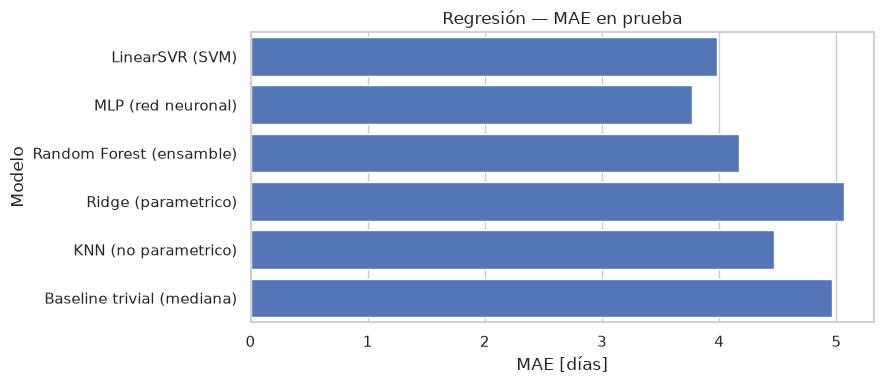

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=reg['ranking'], x='test_MAE', y='model', ax=ax, color='#4472C4')
ax.set(title='Regresión — MAE en prueba', xlabel='MAE [días]', ylabel='Modelo')
plt.tight_layout()
plt.show()

In [16]:
reg['feature_importance'].head(12)

,feature,importance_mean,importance_std
0,customer_state,0.819490,0.046953
1,estimated_delivery_days,0.707545,0.032307
2,payment_value,0.367430,0.016413
3,total_price,0.302244,0.019497
4,total_freight_value,0.117691,0.013451
5,product_category_name,0.088128,0.011702
6,payment_type,0.035478,0.004493
7,item_count,0.032638,0.007615
8,customer_city,0.030018,0.006052
9,seller_count,0.029363,0.002342


In [17]:
reg['reductions']

,reduction,model,original_features,reduced_features,reduction_pct,MAE,RMSE,R2
0,PCA_95pct,LinearSVR (SVM),112,24,78.571429,4.132281,5.834251,0.022176
1,PCA_95pct,MLP (red neuronal),112,24,78.571429,4.062591,5.632137,0.088751
2,UMAP_10d,LinearSVR (SVM),112,10,91.071429,4.840965,6.199883,-0.104225
3,UMAP_10d,MLP (red neuronal),112,10,91.071429,5.470757,6.813656,-0.333678


## 4. Clasificación — probabilidad de entrega tardía

El objetivo binario `late_delivery` vale 1 cuando la entrega real supera la fecha prometida al cliente. La partición temporal, las cinco familias de modelos y el procedimiento de evaluación son idénticos a la tarea de regresión; solo cambian las métricas (ROC-AUC como primaria, más balanced accuracy, F1, precisión y recall). Al final se grafica la matriz de confusión del campeón para inspeccionar el tipo de error dominante.

In [18]:
X_cls, y_cls, dates_cls = modeling_frame(orders, 'late_delivery')
print(f'Filas: {len(X_cls):,}')
print(f'Prevalencia global de retraso: {y_cls.mean():.3f}')

Filas: 96,476
Prevalencia global de retraso: 0.081


In [19]:
cls = run_task('classification', X_cls, y_cls, dates_cls, config)
list(cls.keys())

['parts',
 'cv_results',
 'ranking',
 'models',
 'feature_importance',
 'reductions']

In [20]:
cls['cv_results']

,model,params,primary_cv_mean,primary_cv_worst,primary_cv_ci95_low,primary_cv_ci95_high,fit_seconds,validation_balanced_accuracy,validation_precision,validation_recall,validation_F1,validation_ROC_AUC,validation_avg_precision
0,Random Forest (ensamble),"{'max_depth': 12, 'min_samples_leaf': 2}",0.634859,0.571601,0.461131,0.808587,3.839301,0.559245,0.207651,0.204167,0.175113,0.634859,0.183613
1,Random Forest (ensamble),"{'max_depth': 12, 'min_samples_leaf': 1}",0.633006,0.563386,0.449838,0.816175,3.863772,0.557446,0.202805,0.195985,0.170778,0.633006,0.182229
2,Random Forest (ensamble),"{'max_depth': 12, 'min_samples_leaf': 5}",0.632210,0.564981,0.450062,0.814357,3.826712,0.561604,0.199160,0.219416,0.181533,0.632210,0.183135
3,Random Forest (ensamble),"{'max_depth': 24, 'min_samples_leaf': 1}",0.630272,0.563409,0.456119,0.804424,4.590936,0.506024,0.244913,0.015161,0.028526,0.630272,0.176799
4,Random Forest (ensamble),"{'max_depth': 24, 'min_samples_leaf': 2}",0.626913,0.564896,0.441821,0.812004,4.541373,0.515784,0.455694,0.040230,0.068622,0.626913,0.179456
5,Logistica (parametrico),{'C': 0.1},0.626373,0.564128,0.468631,0.784115,3.067046,0.573059,0.156394,0.373092,0.213072,0.626373,0.163258
6,Logistica (parametrico),{'C': 1.0},0.625526,0.563383,0.468507,0.782546,5.183363,0.574257,0.157140,0.378019,0.215002,0.625526,0.163428
7,LinearSVC (SVM),{'C': 0.1},0.625293,0.564514,0.471632,0.778954,1.306989,0.575257,0.157361,0.380426,0.216647,0.625293,0.163090
8,Logistica (parametrico),{'C': 10.0},0.625196,0.563383,0.468829,0.781564,7.096981,0.574311,0.157074,0.378667,0.215038,0.625196,0.163137
9,LinearSVC (SVM),{'C': 1.0},0.624942,0.564254,0.471356,0.778527,1.724268,0.575275,0.157250,0.381042,0.216653,0.624942,0.163037


In [21]:
cls['ranking']

,model,best_params,cv_mean,cv_worst,fit_seconds,train_balanced_accuracy,train_precision,train_recall,train_F1,train_ROC_AUC,...,validation_avg_precision,test_balanced_accuracy,test_precision,test_recall,test_F1,test_ROC_AUC,test_avg_precision,test_primary,test_ci95_low,test_ci95_high
0,MLP (red neuronal),"{'alpha': 0.0001, 'hidden_layer_sizes': (64, 3...",0.609677,0.535046,7.881443,0.502928,0.651163,0.006136,0.012158,0.764545,...,0.251990,0.500000,0.000000,0.000000,0.000000,0.674767,0.085994,0.674767,0.660311,0.688427
1,Random Forest (ensamble),"{'max_depth': 12, 'min_samples_leaf': 2}",0.634859,0.571601,4.712152,0.756873,0.258094,0.681350,0.374375,0.865473,...,0.274730,0.516267,0.067837,0.140059,0.091403,0.545780,0.061153,0.545780,0.528790,0.563645
2,Logistica (parametrico),{'C': 0.1},0.626373,0.564128,3.673451,0.636812,0.134115,0.611440,0.219980,0.686958,...,0.224870,0.676867,0.090939,0.801175,0.163339,0.714846,0.110266,0.714846,0.701448,0.728515
3,LinearSVC (SVM),{'C': 0.1},0.625293,0.564514,1.899039,0.637051,0.134552,0.609687,0.220452,0.687142,...,0.223836,0.675102,0.091500,0.786484,0.163928,0.709374,0.109762,0.709374,0.696081,0.723096
4,KNN (no parametrico),"{'n_neighbors': 41, 'weights': 'distance'}",0.569325,0.537459,15.525351,0.999890,1.000000,0.999781,0.999890,1.000000,...,0.182145,0.500000,0.000000,0.000000,0.000000,0.563065,0.063975,0.563065,0.545876,0.580679
5,Baseline trivial (clase mayoritaria),{'strategy': 'most_frequent'},0.500000,0.500000,0.677689,0.500000,0.000000,0.000000,0.000000,0.500000,...,0.116248,0.500000,0.000000,0.000000,0.000000,0.500000,0.052913,0.500000,0.500000,0.500000


In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

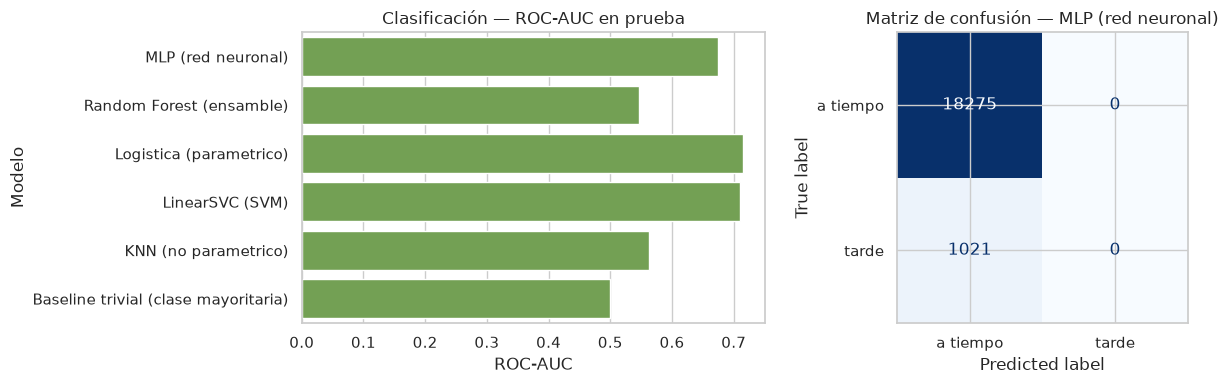

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.barplot(data=cls['ranking'], x='test_ROC_AUC', y='model', ax=axes[0], color='#70AD47')
axes[0].set(title='Clasificación — ROC-AUC en prueba', xlabel='ROC-AUC', ylabel='Modelo')

champion = cls['ranking'].iloc[0]['model']
champion_model = cls['models'][champion]
ConfusionMatrixDisplay.from_predictions(
    cls['parts']['y_test'],
    champion_model.predict(cls['parts']['X_test']),
    display_labels=['a tiempo', 'tarde'],
    cmap='Blues',
    ax=axes[1],
    colorbar=False,
)
axes[1].set_title(f'Matriz de confusión — {champion}')

plt.tight_layout()
plt.show()

In [24]:
cls['feature_importance'].head(12)

,feature,importance_mean,importance_std
0,customer_state,0.128088,0.004924
1,estimated_delivery_days,0.110588,0.008404
2,total_freight_value,0.074380,0.010517
3,product_category_name,0.024588,0.001956
4,purchase_month,0.020526,0.003467
5,item_count,0.018327,0.004442
6,mean_product_width_cm,0.011158,0.002221
7,payment_value,0.009640,0.002063
8,seller_count,0.006916,0.001361
9,payment_type,0.005602,0.002836


In [25]:
cls['reductions']

,reduction,model,original_features,reduced_features,reduction_pct,balanced_accuracy,precision,recall,F1,ROC_AUC,avg_precision
0,PCA_95pct,MLP (red neuronal),112,24,78.571429,0.500000,0.000000,0.000000,0.000000,0.564145,0.067111
1,PCA_95pct,Random Forest (ensamble),112,24,78.571429,0.492442,0.048746,0.167483,0.075513,0.570156,0.060364
2,UMAP_10d,MLP (red neuronal),112,10,91.071429,0.500000,0.000000,0.000000,0.000000,0.415880,0.043197
3,UMAP_10d,Random Forest (ensamble),112,10,91.071429,0.480796,0.041012,0.125367,0.061806,0.396467,0.043258


## 5. Persistencia de resultados

Guardamos las cuatro tablas por tarea (resultados de CV, ranking, importancia de variables, reducciones) y un `summary.json` compacto en la carpeta del experimento. Estos archivos son la evidencia reproducible; el reporte final consume los `summary.json` para citar los números principales. El análisis detallado —por qué el ROC-AUC colapsa en test y cómo influye el *shift* temporal entre particiones— se documenta en el `README.md` de la misma carpeta.

In [26]:
import json

In [27]:
output = root / 'outputs' / 'experimentos' / '01_baseline_pre_compra'
output.mkdir(parents=True, exist_ok=True)
output

PosixPath('/home/mateo/Documentos/UdeA/ModelosSimulaciónII/proyectoEntregas/LogisTech-Modelos-Simulacion-II/outputs/experimentos/01_baseline_pre_compra')

In [28]:
for prefix, result in [('regression', reg), ('classification', cls)]:
    for name in ['cv_results', 'ranking', 'feature_importance', 'reductions']:
        result[name].to_csv(output / f'{prefix}_{name}.csv', index=False)

print('Tablas guardadas.')

Tablas guardadas.


In [29]:
def _headline(result: dict, primary_col: str) -> dict:
    top = result['ranking'].iloc[0]
    return {
        'champion': top['model'],
        'test_primary': float(top[primary_col]),
        'test_ci95': [float(top['test_ci95_low']), float(top['test_ci95_high'])],
    }

summary = {
    'sample_rows': MAX_ROWS,
    'cv_splits': config.cv_splits,
    'bootstrap_iterations': config.bootstrap_iterations,
    'regression': _headline(reg, 'test_MAE'),
    'classification': _headline(cls, 'test_ROC_AUC'),
}
(output / 'summary.json').write_text(
    json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8'
)
summary

{'sample_rows': None,
 'cv_splits': 3,
 'bootstrap_iterations': 500,
 'regression': {'champion': 'LinearSVR (SVM)',
  'test_primary': 3.979647162704609,
  'test_ci95': [3.922299705648949, 4.036764568215699]},
 'classification': {'champion': 'MLP (red neuronal)',
  'test_primary': 0.6747671269952074,
  'test_ci95': [0.6603114890517523, 0.6884271227161061]}}